# F5 — Figuras del contraste estadístico (F5.1–F5.6), F4.5 y F4.6 (parcial)

**Procedencia.**
- Ejecución confirmatoria de la Fase 5: `run_fase5 --ejecutar-prueba`, una sola vez, desde HEAD `dd2e462`, que es la etiqueta `enmienda-5`. Sus resultados se commitearon en `e02104f`.
- F4.6: `run_fase5 --analisis-f46` desde `e02104f`, con resultados en `43d933c`.
- Este notebook **no ejecuta `run_fase5`** y no calcula estadísticos nuevos.
- Todas las cifras salen de `results/f5_contraste/resultados.json`, `f46_resultados.json` y `results/canonical_numbers.json`.
- Excepción: para graficar las distribuciones θ\* y D\* (figura 4), las réplicas se reconstruyen con `src/protocol`, con los mismos índices de A1 y el mismo código. Antes se comprueba que reproducen `resultados.json` con una tolerancia de 1e-12.
- Excepción descriptiva: los conteos del diagrama de intersección de errores (figura 10c) salen de las mismas predicciones. Antes se comprueba que reproducen los tamaños por par de `f46_resultados.json`.

**Regla de lectura.**
- **«No se detecta pérdida»** no es lo mismo que «la imagen mejora» o que «supera a BETO»: los intervalos de las tres etapas de la descomposición contienen 0, y la desigualdad de procesamiento de datos acota la información, no el F1 de un estimador.
- **V1 no es equivalencia** con BETO: indica que la imagen conserva al menos la mitad de la capacidad de BETO por encima del azar (r = 0.50).
- La no significancia de McNemar tampoco es equivalencia.

**Convenciones de las figuras.**
- n = 114 muestras de prueba (70 no depresivas y 44 depresivas).
- F1-Macro adimensional, en [0, 1].
- Colores y marcadores por técnica, iguales en todas las figuras (`src/viz/style.py`, paleta validada para daltonismo). Toda serie lleva también su etiqueta de texto.
- PNG a 300 dpi en `results/f5_contraste/figures/`.

In [1]:
import hashlib
import json
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Circle

T0 = time.time()
REPO = Path.cwd().resolve()
if not (REPO / 'src').is_dir():
    REPO = REPO.parent
for p in (REPO, REPO / 'src'):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
from viz import style

style.apply()
OUT = REPO / 'results' / 'f5_contraste'
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)

RES_DOC = json.loads((OUT / 'resultados.json').read_text(encoding='utf-8'))
F46_DOC = json.loads((OUT / 'f46_resultados.json').read_text(encoding='utf-8'))
CANON = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['numbers']
R, F46 = RES_DOC['resultados'], F46_DOC['resultados']
OBS = R['observados']

TECHS = ['gray_scott', 'perlin', 'lorenz']
SEEDS = [42, 7, 123, 2024, 99]
LAB = style.TECH_LABEL
COL = style.TECH_COLOR
MARK = {'gray_scott': 's', 'perlin': 'o', 'lorenz': '^'}
REF_COL = style.INK
N_NOTE = 'n = 114 muestras de prueba (70 no depresivas, 44 depresivas). F1-Macro adimensional.'
FINALISTA = {'gray_scott': 'EfficientNet-B0 ajuste fino', 'perlin': 'ViT-B/16 congelado', 'lorenz': 'ViT-B/16 congelado'}
SEGUNDO = {'gray_scott': 'ResNet-18 ajuste fino', 'perlin': 'EfficientNet-B0 congelado', 'lorenz': 'EfficientNet-B0 ajuste fino'}
FIGS = []


def o(*key):
    """F1 observado de resultados.json:observados (claves de tupla como en el JSON)."""
    return OBS[key[0]] if len(key) == 1 else OBS[str(tuple(key))]


def canon_test(nid):
    return CANON[nid]['value']['test']


def pie(fig, text, y=-0.02):
    fig.text(0.01, y, text, ha='left', va='top', fontsize=style.FONT_SIZES['annot'], color=style.INK_SECONDARY, wrap=True)


def guardar(fig, nombre, descripcion):
    path = style.save(fig, FIG / nombre)
    FIGS.append({'archivo': f'results/f5_contraste/figures/{path.name}', 'figura': descripcion})
    plt.show()
    return path


def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def sha_lf(path):
    return hashlib.sha256(Path(path).read_bytes().replace(b'\r\n', b'\n')).hexdigest()

## 0. Procedencia y hashes

In [2]:
meta = RES_DOC['meta']
prov = pd.DataFrame([
    ('HEAD de la ejecución (resultados.json:meta.git_commit)', meta['git_commit']),
    ('Etiqueta de la compuerta', f"{meta['gate_tag']} → {meta['gate_tag_commit']}"),
    ('Commit de los resultados de la Fase 5', 'e02104f'),
    ('HEAD de F4.6 (f46_resultados.json:meta.git_commit)', F46_DOC['meta']['git_commit']),
    ('resultados.json — sha256 (bytes)', sha(OUT / 'resultados.json')),
    ('resultados.json — sha256 (LF; canonical_numbers.json:inputs)', sha_lf(OUT / 'resultados.json')),
    ('f46_resultados.json — sha256 (bytes)', sha(OUT / 'f46_resultados.json')),
    ('f46_resultados.json — sha256 (LF; canonical_numbers.json:inputs)', sha_lf(OUT / 'f46_resultados.json')),
    ('Huella de los índices de A1 (idx_sha256)', meta['bootstrap']['idx_sha256']),
], columns=['Campo', 'Valor'])
canon_inputs = json.loads((REPO / 'results' / 'canonical_numbers.json').read_text(encoding='utf-8'))['inputs']
assert canon_inputs['results/f5_contraste/resultados.json'] == sha_lf(OUT / 'resultados.json')
assert canon_inputs['results/f5_contraste/f46_resultados.json'] == sha_lf(OUT / 'f46_resultados.json')
assert F46_DOC['meta']['inputs'] == meta['inputs'] and F46_DOC['meta']['bootstrap'] == meta['bootstrap']
pd.set_option('display.max_colwidth', 120)
prov

,Campo,Valor
0,HEAD de la ejecución (resultados.json:meta.git_commit),dd2e462ca7d2f40326392da6997916a34c7c3606
1,Etiqueta de la compuerta,enmienda-5 → dd2e462ca7d2f40326392da6997916a34c7c3606
2,Commit de los resultados de la Fase 5,e02104f
3,HEAD de F4.6 (f46_resultados.json:meta.git_commit),e02104fcb15affed677a64b972305bc72f97c325
4,resultados.json — sha256 (bytes),42c0ed12ab271bea2b8ddbd2b1f6dfad31c8396ff6ae720751a632d79c752261
5,resultados.json — sha256 (LF; canonical_numbers.json:inputs),42c0ed12ab271bea2b8ddbd2b1f6dfad31c8396ff6ae720751a632d79c752261
6,f46_resultados.json — sha256 (bytes),f77c5ea2d628ccb9137a6a9b64ba89077de9dec5e88abcfe0e081887fb7109ce
7,f46_resultados.json — sha256 (LF; canonical_numbers.json:inputs),f77c5ea2d628ccb9137a6a9b64ba89077de9dec5e88abcfe0e081887fb7109ce
8,Huella de los índices de A1 (idx_sha256),322edaaa5f1175bb4d4a16409d7f852fa7e67fa5daa8a504bb4976e67d0a7e37


## 1. F1-Macro de prueba de todos los modelos

Cada fila es un clasificador.
- Los modelos visuales muestran sus cinco semillas (marcadores huecos) y su media (marcador lleno).
- La línea roja discontinua es el umbral equivalente de F1 visual para θ = 0, `f12.umbral_f1_visual` = 0.6019.
- La línea negra punteada es el F1 de BETO (0.7039).

Fuentes: `resultados.json:observados` y `canonical_numbers.json`.

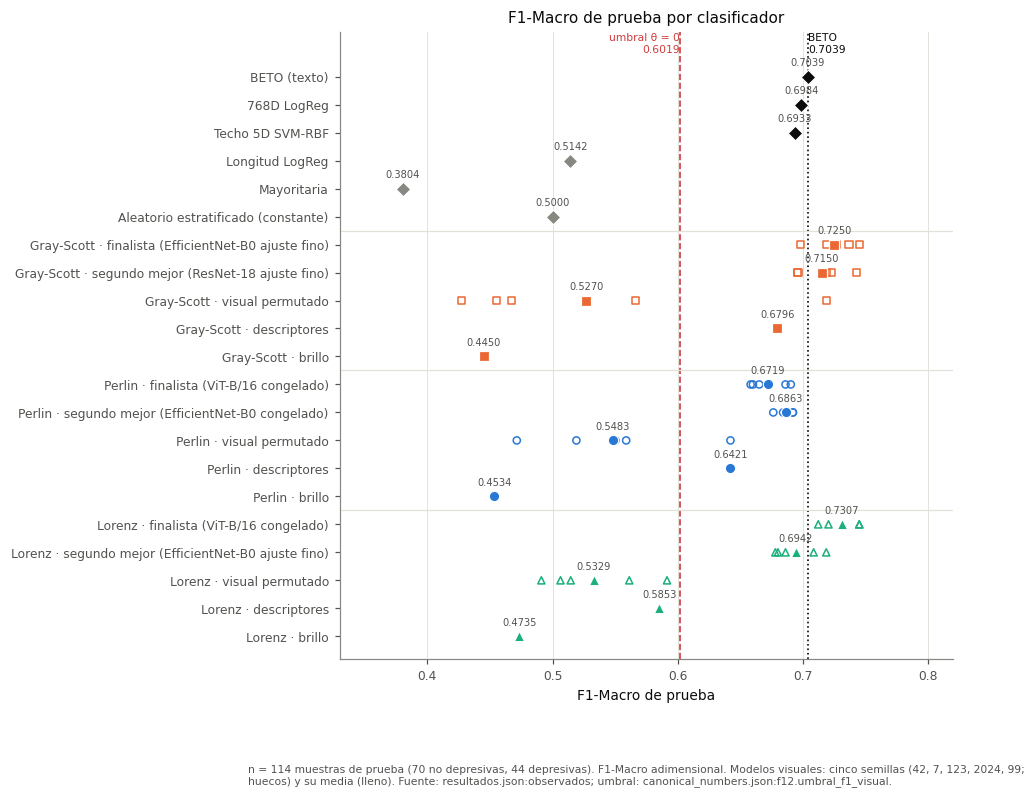

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f5_01_f1_prueba_modelos.png')

In [3]:
rows = []   # (etiqueta, valores, color, marcador, grupo)
rows += [('BETO (texto)', [o('beto')], REF_COL, 'D', 'Referencias'),
         ('768D LogReg', [o('emb768')], REF_COL, 'D', 'Referencias'),
         ('Techo 5D SVM-RBF', [o('techo5d')], REF_COL, 'D', 'Referencias'),
         ('Longitud LogReg', [o('longitud')], style.MUTED, 'D', 'Referencias'),
         ('Mayoritaria', [o('majority')], style.MUTED, 'D', 'Referencias'),
         ('Aleatorio estratificado (constante)', [R['principal']['techniques']['gray_scott']['piso_f1_obs']['stratified']],
          style.MUTED, 'D', 'Referencias')]
for t in TECHS:
    rows += [(f'{LAB[t]} · finalista ({FINALISTA[t]})', o('img', 'final', t), COL[t], MARK[t], LAB[t]),
             (f'{LAB[t]} · segundo mejor ({SEGUNDO[t]})', o('img', 'sensibilidad', t), COL[t], MARK[t], LAB[t]),
             (f'{LAB[t]} · visual permutado', o('img', 'control_permutacion', t), COL[t], MARK[t], LAB[t]),
             (f'{LAB[t]} · descriptores', [o('descriptors', t)], COL[t], MARK[t], LAB[t]),
             (f'{LAB[t]} · brillo', [o('brightness', t)], COL[t], MARK[t], LAB[t])]

fig, ax = plt.subplots(figsize=(7.2, 7.4))
ypos = np.arange(len(rows))[::-1]
for y, (lab, vals, c, m, g) in zip(ypos, rows):
    vals = np.asarray(vals, dtype=float)
    if len(vals) > 1:
        ax.scatter(vals, np.full(len(vals), y), s=22, facecolors='none', edgecolors=c, marker=m, linewidths=1.0, zorder=3)
    ax.scatter([vals.mean()], [y], s=46, color=c, marker=m, edgecolors='white', linewidths=0.8, zorder=4)
    ax.text(vals.mean(), y + 0.32, f'{vals.mean():.4f}', ha='center', va='bottom', fontsize=6.5, color=style.INK_SECONDARY)
umbral, beto = canon_test('f12.umbral_f1_visual'), o('beto')
ax.axvline(umbral, color=style.THRESHOLD_COLOR, ls='--', lw=1.1, zorder=1)
ax.axvline(beto, color=style.INK, ls=':', lw=1.1, zorder=1)
ax.text(umbral, len(rows) - 0.2, f'umbral θ = 0\n{umbral:.4f}', color=style.THRESHOLD_COLOR, ha='right', va='bottom', fontsize=7)
ax.text(beto, len(rows) - 0.2, f'BETO\n{beto:.4f}', color=style.INK, ha='left', va='bottom', fontsize=7)
for y in (ypos[5] - 0.5, ypos[10] - 0.5, ypos[15] - 0.5):
    ax.axhline(y, color=style.GRID, lw=0.8)
ax.set_yticks(ypos, [r[0] for r in rows])
ax.set_xlabel('F1-Macro de prueba')
ax.set_xlim(0.33, 0.82)
ax.set_ylim(-0.8, len(rows) + 0.6)
ax.grid(axis='x')
ax.set_title('F1-Macro de prueba por clasificador')
pie(fig, N_NOTE + ' Modelos visuales: cinco semillas (42, 7, 123, 2024, 99; huecos) y su media (lleno). '
    'Fuente: resultados.json:observados; umbral: canonical_numbers.json:f12.umbral_f1_visual.')
guardar(fig, 'f5_01_f1_prueba_modelos', 'F1-Macro de prueba de todos los clasificadores, con umbral θ = 0 y BETO')

**Lectura.**
- Los tres finalistas quedan por encima del umbral equivalente (0.6019), con todas sus semillas.
- Los controles permutados, el brillo, la longitud y la mayoritaria quedan por debajo.
- Que el F1 medio de Gray-Scott y de Lorenz quede a la derecha de la línea de BETO no se lee como una ganancia: véanse la figura 5 y la regla de lectura.

## 2. F5.2 — No inferioridad: θ por técnica y en cada variante de sensibilidad

θ_t = (F1_img − 0.5) − r (F1_BETO − 0.5); H₁: θ > 0.
- Los IC son percentiles bilaterales al nivel 1 − 2α_h de Holm, indicado en cada barra.
- En la formulación A, el estadístico graficado es δ − Δ (Enmienda 4, A13).

Fuentes: `resultados.json:principal` y `sensibilidad`.

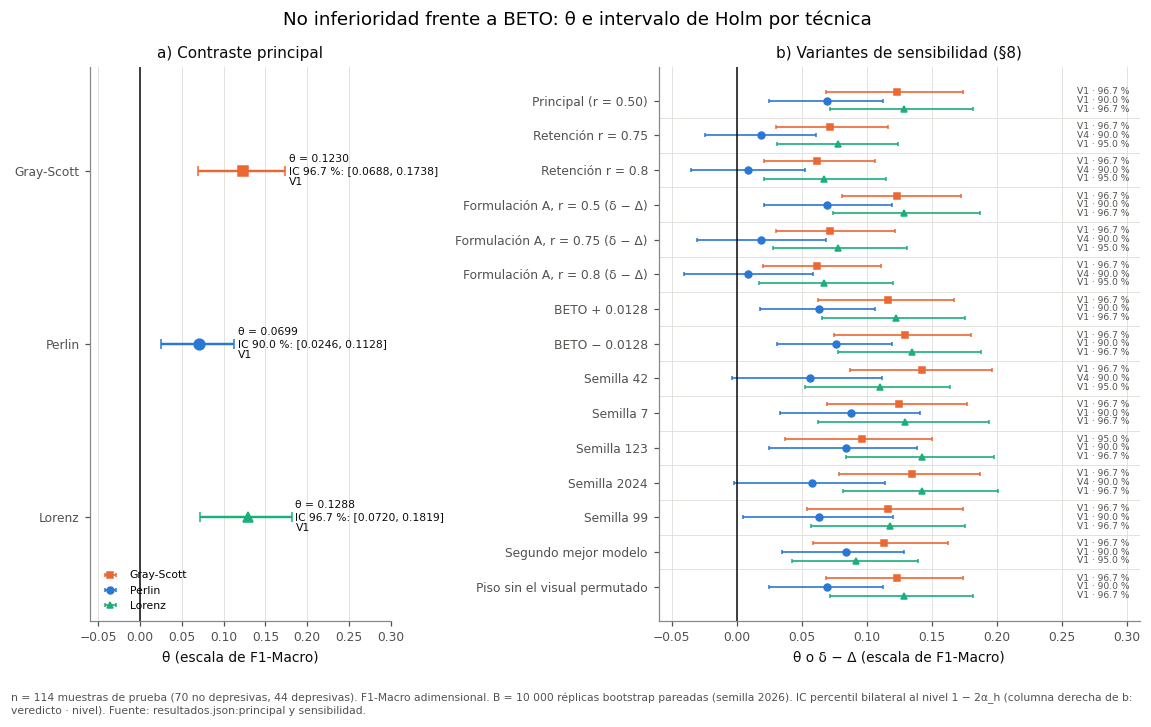

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f5_02_theta_forest.png')

In [4]:
def theta_rows():
    S = R['sensibilidad']
    out = [('Principal (r = 0.50)', R['principal'])]
    out += [(f'Retención r = {k.split("=")[1]}', v) for k, v in S['retencion_exigida'].items()]
    out += [(f'Formulación A, r = {k.split("=")[1]} (δ − Δ)', v) for k, v in S['formulacion_A'].items()]
    for k, v in S['variabilidad_beto'].items():
        out.append((f'BETO {"+" if k.startswith("+") else "−"} 0.0128', v))
    out += [(f'Semilla {s}', v) for s, v in S['por_semilla']['por_semilla'].items()]
    out += [('Segundo mejor modelo', S['segundo_mejor']), ('Piso sin el visual permutado', S['piso_sin_permutado'])]
    return out


fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 6.2), gridspec_kw={'width_ratios': [1, 1.6]})
for i, t in enumerate(TECHS):
    r = R['principal']['techniques'][t]
    lo, hi = r['theta_interval']
    y = len(TECHS) - 1 - i
    a1.errorbar(r['theta_obs'], y, xerr=[[r['theta_obs'] - lo], [hi - r['theta_obs']]], fmt=MARK[t], color=COL[t],
                ms=7, capsize=3, lw=1.6)
    a1.text(hi + 0.004, y, f"θ = {r['theta_obs']:.4f}\nIC {r['interval_level']*100:.1f} %: [{lo:.4f}, {hi:.4f}]\n{r['verdict']}",
            va='center', fontsize=7, color=style.INK)
a1.axvline(0, color=style.INK, lw=1)
a1.set_yticks(range(len(TECHS)), [LAB[t] for t in TECHS[::-1]])
a1.set_xlim(-0.06, 0.30)
a1.set_ylim(-0.6, 2.6)
a1.set_xlabel('θ (escala de F1-Macro)')
a1.set_title('a) Contraste principal')
a1.grid(axis='x')

rows = theta_rows()
off = {'gray_scott': 0.25, 'perlin': 0.0, 'lorenz': -0.25}
for j, (lab, res) in enumerate(rows):
    y = len(rows) - 1 - j
    for t in TECHS:
        r = res['techniques'][t]
        lo, hi = r['theta_interval']
        a2.errorbar(r['theta_obs'], y + off[t], xerr=[[r['theta_obs'] - lo], [hi - r['theta_obs']]], fmt=MARK[t],
                    color=COL[t], ms=4.5, capsize=1.5, lw=1.1, label=LAB[t] if j == 0 else None)
        a2.text(0.262, y + off[t], f"{r['verdict']} · {r['interval_level']*100:.1f} %", fontsize=6, va='center',
                color=style.INK_SECONDARY)
    if j:
        a2.axhline(y + 0.5, color=style.GRID, lw=0.6)
a2.axvline(0, color=style.INK, lw=1)
a2.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]])
a2.set_xlim(-0.06, 0.31)
a2.set_xlabel('θ o δ − Δ (escala de F1-Macro)')
a2.set_title('b) Variantes de sensibilidad (§8)')
a1.legend(*a2.get_legend_handles_labels(), loc='lower left', fontsize=7)
a2.grid(axis='x')
fig.suptitle('No inferioridad frente a BETO: θ e intervalo de Holm por técnica')
fig.tight_layout()
pie(fig, N_NOTE + ' B = 10 000 réplicas bootstrap pareadas (semilla 2026). IC percentil bilateral al nivel 1 − 2α_h '
    '(columna derecha de b: veredicto · nivel). Fuente: resultados.json:principal y sensibilidad.')
guardar(fig, 'f5_02_theta_forest', 'F5.2: θ con IC de Holm por técnica (a) y en cada variante de sensibilidad (b)')

**Lectura.**
- En el contraste principal, los tres intervalos de θ excluyen 0 y las tres técnicas obtienen V1.
- En las variantes, Perlin es la única cuyo intervalo cruza 0, lo que da V4 en cuatro casos:
  - r = 0.75 y r = 0.80, en ambas formulaciones;
  - las semillas 42 y 2024.
- Gray-Scott y Lorenz mantienen V1 en todas las variantes.

## 3. F5.1 — Superioridad sobre el piso

a) F1 del finalista (media de 5 semillas) y de cada piso candidato. El piso aplicado, el de mayor F1 de prueba observado (Enmienda 4, A2), está destacado.
b) D = F1_img − F1_piso, con su IC de Holm.

Fuente: `resultados.json:principal.techniques.<t>`.

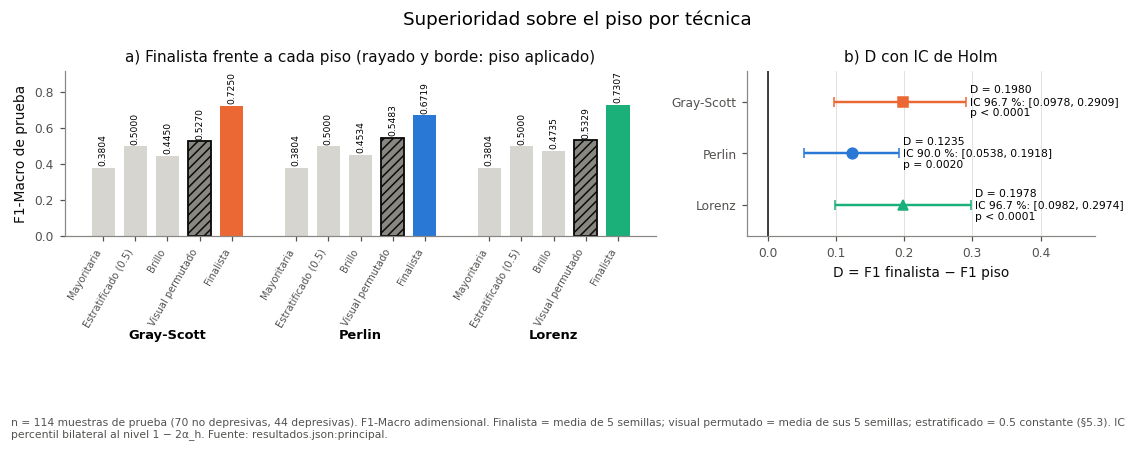

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f5_03_superioridad_piso.png')

In [5]:
PISO_LAB = {'majority': 'Mayoritaria', 'stratified': 'Estratificado (0.5)', 'brightness': 'Brillo',
            'visual_permutado': 'Visual permutado'}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4.4), gridspec_kw={'width_ratios': [1.7, 1]})
cats = list(PISO_LAB) + ['finalista']
for i, t in enumerate(TECHS):
    r = R['principal']['techniques'][t]
    x0 = i * (len(cats) + 1)
    for k, name in enumerate(cats):
        v = r['f1_img_obs'] if name == 'finalista' else r['piso_f1_obs'][name]
        applied = name in r['piso']
        c = COL[t] if name == 'finalista' else (style.MUTED if applied else '#d6d5cf')
        a1.bar(x0 + k, v, width=0.72, color=c, edgecolor=style.INK if applied else 'none', linewidth=1.2 if applied else 0,
               hatch='////' if applied else None)
        a1.text(x0 + k, v + 0.01, f'{v:.4f}', ha='center', fontsize=6, rotation=90, va='bottom')
    a1.text(x0 + (len(cats) - 1) / 2, -0.62, LAB[t], ha='center', fontsize=8.5, fontweight='bold', transform=a1.get_xaxis_transform())
ticks = [i * (len(cats) + 1) + k for i in range(3) for k in range(len(cats))]
a1.set_xticks(ticks, [('Finalista' if c == 'finalista' else PISO_LAB[c]) for _ in TECHS for c in cats], rotation=60,
              ha='right', fontsize=6.5)
a1.set_ylabel('F1-Macro de prueba')
a1.set_ylim(0, 0.92)
a1.set_title('a) Finalista frente a cada piso (rayado y borde: piso aplicado)')
for i, t in enumerate(TECHS):
    r = R['principal']['techniques'][t]
    lo, hi = r['D_interval']
    y = 2 - i
    a2.errorbar(r['D_obs'], y, xerr=[[r['D_obs'] - lo], [hi - r['D_obs']]], fmt=MARK[t], color=COL[t], ms=7, capsize=3)
    sp = r['superioridad_piso']
    ptxt = 'p < 0.0001' if sp['below_resolution'] else f"p = {sp['p']:.4f}"
    a2.text(hi + 0.006, y, f"D = {r['D_obs']:.4f}\nIC {r['D_interval_level']*100:.1f} %: [{lo:.4f}, {hi:.4f}]\n{ptxt}",
            va='center', fontsize=7)
a2.axvline(0, color=style.INK, lw=1)
a2.set_yticks([2, 1, 0], [LAB[t] for t in TECHS])
a2.set_xlim(-0.03, 0.48)
a2.set_ylim(-0.6, 2.6)
a2.set_xlabel('D = F1 finalista − F1 piso')
a2.set_title('b) D con IC de Holm')
a2.grid(axis='x')
fig.suptitle('Superioridad sobre el piso por técnica')
fig.tight_layout()
pie(fig, N_NOTE + ' Finalista = media de 5 semillas; visual permutado = media de sus 5 semillas; estratificado = 0.5 '
    'constante (§5.3). IC percentil bilateral al nivel 1 − 2α_h. Fuente: resultados.json:principal.', y=0.14)
guardar(fig, 'f5_03_superioridad_piso', 'F5.1: finalista frente a cada piso (a) y D con IC de Holm (b)')

**Lectura.**
- En las tres técnicas, el piso aplicado es el visual permutado, sin empate.
- D es positivo y su intervalo excluye 0: Holm rechaza en las tres.
- El brillo de Perlin (0.4534 en prueba) queda por debajo del permutado.

## 4. Distribuciones bootstrap de θ\* y D\* (réplicas reconstruidas)

Las réplicas se reconstruyen con `src/protocol`, sin ejecutar `run_fase5`:
- índices de A1 con `bootstrap.indices`;
- predicciones de prueba ya archivadas, con `insumos.cargar`;
- tabla de F1 con `contraste.f1_table`;
- θ\* y D\* con `contraste.theta_reps` / `contraste.d_reps`.

**Comprobación previa.** Antes de graficar, se verifica lo siguiente (tolerancia 1e-12). Si algo no coincide, la celda se detiene.
- El `idx_sha256` y los hashes de los 56 insumos coinciden con `resultados.json:meta`.
- θ_obs, D_obs, los p (#{rep ≤ 0}/B) y los IC (nivel 1 − 2α_h) reproducen `resultados.json:principal`.
- Además, `contraste.contraste()` reproduce todo el bloque principal.

In [6]:
from src.protocol import bootstrap as bs
from src.protocol import contraste as cx
from src.protocol import insumos as ins_mod
from src.protocol import verdict
from src.protocol.run_fase5 import predicciones   # función de cálculo; no ejecuta ningún modo de run_fase5

TOL = 1e-12
cfg = ins_mod.load_config()
idx = bs.indices(cfg)
idx_sha = hashlib.sha256(np.ascontiguousarray(idx, dtype=np.int64).tobytes()).hexdigest()
checks = [('idx_sha256', idx_sha, meta['bootstrap']['idx_sha256'], idx_sha == meta['bootstrap']['idx_sha256'])]
if not checks[0][3]:
    raise RuntimeError('DETENIDO: idx_sha256 no coincide con resultados.json')
ins = ins_mod.cargar(cfg, with_u=False)
same_inputs = ins.files == meta['inputs']
checks.append(('sha256 de los 56 insumos', len(ins.files), len(meta['inputs']), same_inputs))
if not same_inputs:
    raise RuntimeError('DETENIDO: los insumos no coinciden con resultados.json:meta.inputs')

W = bs.weights(idx, len(ins.y))
FT = cx.f1_table(W, ins.y, predicciones(ins, cfg))
c = cfg['contraste']
b_obs, b_rep = cx.ref(FT, 'beto')
REPS = {}
for t in TECHS:
    r = R['principal']['techniques'][t]
    i_obs, i_rep = cx.img(FT, 'final', t)
    th_obs, th_rep = cx.theta_reps(i_obs, b_obs, c['r'], c['f1_azar']), cx.theta_reps(i_rep, b_rep, c['r'], c['f1_azar'])
    d_obs, d_rep, info = cx.d_reps(i_obs, i_rep, cx.floor_candidates(FT, t, cfg), 'identidad', 'min', cx.empate_tolerancia(cfg))
    REPS[t] = {'theta': th_rep, 'D': d_rep}
    a_ni, a_sp = r['no_inferioridad']['alpha_h'], r['superioridad_piso']['alpha_h']
    pairs = [
        ('θ_obs', th_obs, r['theta_obs']),
        ('p no inferioridad', verdict.p_value(th_rep)[0], r['no_inferioridad']['p']),
        ('IC θ inferior', verdict.percentile_interval(th_rep, a_ni)[0], r['theta_interval'][0]),
        ('IC θ superior', verdict.percentile_interval(th_rep, a_ni)[1], r['theta_interval'][1]),
        ('D_obs', d_obs, r['D_obs']),
        ('p superioridad', verdict.p_value(d_rep)[0], r['superioridad_piso']['p']),
        ('IC D inferior', bs.percentile_interval(d_rep, a_sp, 1 - a_sp)[0], r['D_interval'][0]),
        ('IC D superior', bs.percentile_interval(d_rep, a_sp, 1 - a_sp)[1], r['D_interval'][1]),
        ('F1 visual', i_obs, r['f1_img_obs']), ('F1 BETO', b_obs, r['f1_beto_obs']),
    ]
    for name, mine, theirs in pairs:
        checks.append((f'{LAB[t]} · {name}', mine, theirs, abs(mine - theirs) <= TOL))
    checks.append((f'{LAB[t]} · piso aplicado', info['piso'], r['piso'], info['piso'] == r['piso']))

full = cx.contraste(FT, cfg)
for t in TECHS:
    a, b = full['techniques'][t], R['principal']['techniques'][t]
    for k in ('theta_obs', 'D_obs'):
        checks.append((f'{LAB[t]} · contraste() {k}', a[k], b[k], abs(a[k] - b[k]) <= TOL))
    for k in ('no_inferioridad', 'superioridad_piso'):
        checks.append((f'{LAB[t]} · contraste() {k}.p / rechazo', (a[k]['p'], a[k]['reject']), (b[k]['p'], b[k]['reject']),
                       abs(a[k]['p'] - b[k]['p']) <= TOL and a[k]['reject'] == b[k]['reject']))
    checks.append((f'{LAB[t]} · contraste() veredicto', a['verdict'], b['verdict'], a['verdict'] == b['verdict']))
checks.append(('contraste() veredicto global', full['global'], R['principal']['global'], full['global'] == R['principal']['global']))

CHECK = pd.DataFrame(checks, columns=['Comprobación', 'Reconstruido', 'resultados.json', 'Coincide'])
n_ok = int(CHECK['Coincide'].sum())
REPRO = {'tolerancia': TOL, 'comprobaciones': len(CHECK), 'coinciden': n_ok, 'idx_sha256': idx_sha,
         'max_abs_diff': float(max(abs(float(a) - float(b)) for a, b in zip(CHECK['Reconstruido'], CHECK['resultados.json'])
                                   if isinstance(a, (float, np.floating)) and isinstance(b, (float, int)))),
         'detalle': [{'comprobacion': r[0], 'coincide': bool(r[3])} for r in checks]}
(FIG / 'reproduccion_replicas.json').write_text(json.dumps(REPRO, indent=1, ensure_ascii=False) + '\n', encoding='utf-8')
print(f'{n_ok}/{len(CHECK)} comprobaciones coinciden (tolerancia {TOL}); máx. |diferencia| = {REPRO["max_abs_diff"]:.3e}')
if n_ok != len(CHECK):
    display(CHECK[~CHECK['Coincide']])
    raise RuntimeError('DETENIDO: las réplicas reconstruidas no reproducen resultados.json')
CHECK

51/51 comprobaciones coinciden (tolerancia 1e-12); máx. |diferencia| = 0.000e+00


,Comprobación,Reconstruido,resultados.json,Coincide
0,idx_sha256,322edaaa5f1175bb4d4a16409d7f852fa7e67fa5daa8a504bb4976e67d0a7e37,322edaaa5f1175bb4d4a16409d7f852fa7e67fa5daa8a504bb4976e67d0a7e37,True
1,sha256 de los 56 insumos,56,56,True
2,Gray-Scott · θ_obs,0.12305,0.12305,True
3,Gray-Scott · p no inferioridad,0.0,0.0,True
4,Gray-Scott · IC θ inferior,0.068808,0.068808,True
5,Gray-Scott · IC θ superior,0.173798,0.173798,True
6,Gray-Scott · D_obs,0.198022,0.198022,True
7,Gray-Scott · p superioridad,0.0,0.0,True
8,Gray-Scott · IC D inferior,0.097827,0.097827,True
9,Gray-Scott · IC D superior,0.290869,0.290869,True


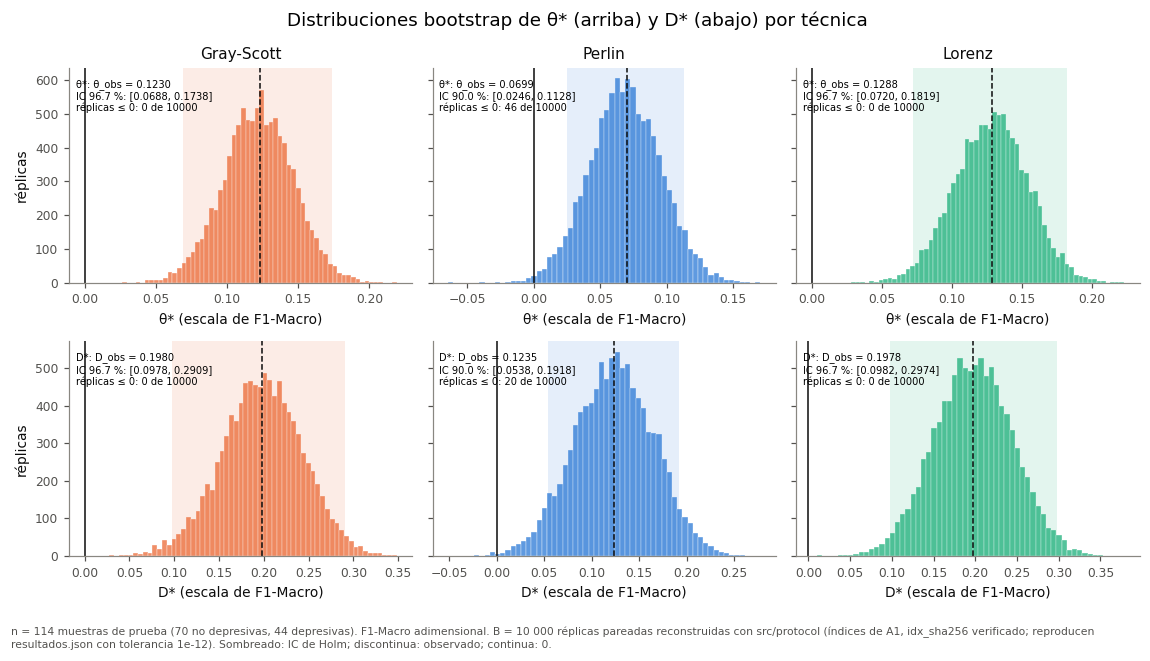

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f5_04_distribuciones_bootstrap.png')

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(10.5, 5.6), sharey='row')
for j, t in enumerate(TECHS):
    r = R['principal']['techniques'][t]
    for i, (key, obs_k, ic_k, lev_k, sym) in enumerate([('theta', 'theta_obs', 'theta_interval', 'interval_level', 'θ*'),
                                                          ('D', 'D_obs', 'D_interval', 'D_interval_level', 'D*')]):
        ax = axes[i, j]
        reps = REPS[t][key]
        lo, hi = r[ic_k]
        ax.hist(reps, bins=60, color=COL[t], alpha=0.75, edgecolor='white', linewidth=0.3)
        ax.axvspan(lo, hi, color=COL[t], alpha=0.12, lw=0)
        ax.axvline(0, color=style.INK, lw=1)
        ax.axvline(r[obs_k], color=style.INK, lw=1, ls='--')
        n_le0 = int(np.sum(reps <= 0))
        ax.text(0.02, 0.95, f"{sym}: {sym[0]}_obs = {r[obs_k]:.4f}\nIC {r[lev_k]*100:.1f} %: [{lo:.4f}, {hi:.4f}]\n"
                f"réplicas ≤ 0: {n_le0} de {len(reps)}", transform=ax.transAxes, va='top', fontsize=6.5)
        ax.set_xlabel(f'{sym} (escala de F1-Macro)')
        if j == 0:
            ax.set_ylabel('réplicas')
        if i == 0:
            ax.set_title(f'{LAB[t]}')
fig.suptitle('Distribuciones bootstrap de θ* (arriba) y D* (abajo) por técnica')
fig.tight_layout()
pie(fig, N_NOTE + ' B = 10 000 réplicas pareadas reconstruidas con src/protocol (índices de A1, idx_sha256 verificado; '
    'reproducen resultados.json con tolerancia 1e-12). Sombreado: IC de Holm; discontinua: observado; continua: 0.')
guardar(fig, 'f5_04_distribuciones_bootstrap', 'Distribuciones bootstrap de θ* y D* por técnica (réplicas reconstruidas y verificadas)')

**Lectura.**
- En Gray-Scott y en Lorenz, ninguna réplica de θ\* ni de D\* es ≤ 0. Por eso se reporta p < 1/B.
- En Perlin, la fracción de réplicas ≤ 0 es el p reportado: 0.0046 en no inferioridad y 0.0020 en superioridad.

## 5. F5.3 — Descomposición de la pérdida y comparación con descriptores

a) Cascada por técnica: F1 de BETO → 768D → techo 5D → finalista visual.
- Cada tramo es una etapa: cabeza, reducción y renderizado.
- La barra de error marca el IC al 95 % del nivel al final del tramo, es decir, el nivel previo menos el IC de la etapa.
- La cabeza y la reducción no dependen de la técnica.

b) Visual − descriptores con IC al 95 %.

Fuentes: `resultados.json:descomposicion`, `frente_a_descriptores` y `observados`.

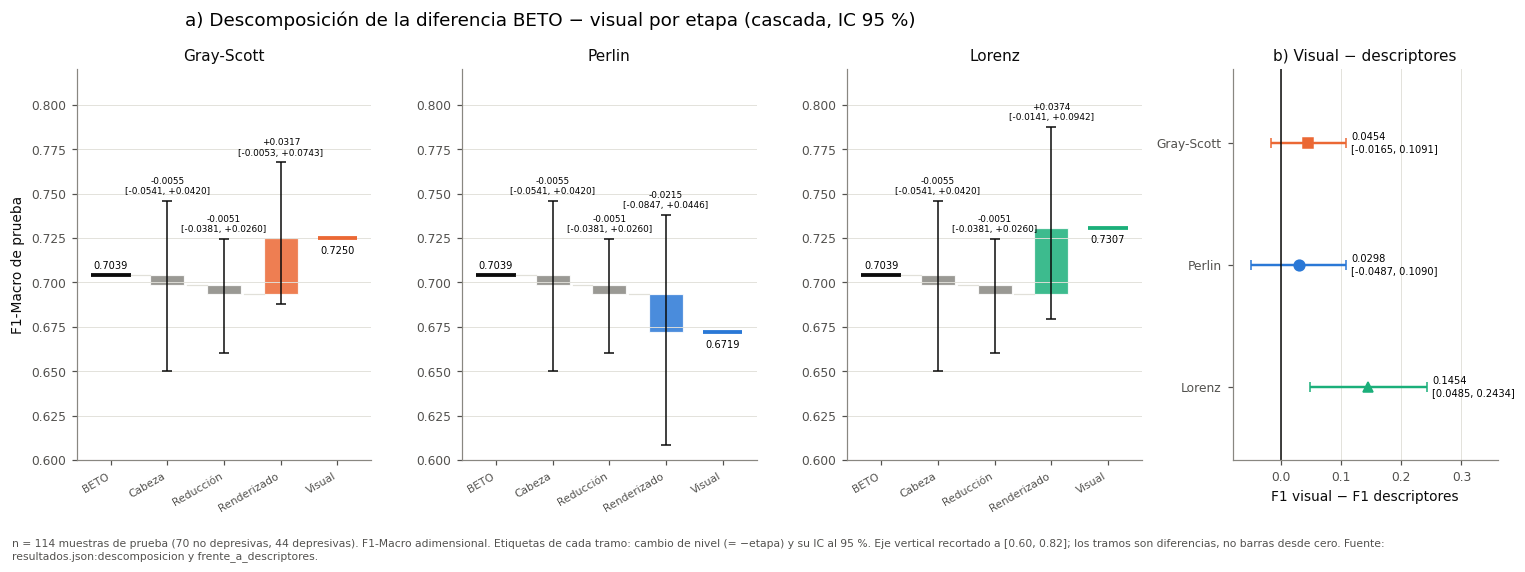

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f5_05_descomposicion_descriptores.png')

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1, 1, 1, 0.9]})
STAGES = [('cabeza', 'Cabeza'), ('reduccion', 'Reducción'), ('renderizado', 'Renderizado')]
for j, t in enumerate(TECHS):
    ax = axes[j]
    d = R['descomposicion'][t]
    level = o('beto')
    xs = ['BETO'] + [s[1] for s in STAGES] + ['Visual']
    ax.hlines(level, -0.35, 0.35, color=style.INK, lw=2.5)
    ax.text(0, level + 0.003, f'{level:.4f}', ha='center', va='bottom', fontsize=6.5)
    for k, (key, _) in enumerate(STAGES, start=1):
        step = d[key]['obs']
        lo, hi = d[key]['interval']
        new = level - step
        ax.bar(k, new - level, bottom=level, width=0.6, color=COL[t] if key == 'renderizado' else style.MUTED,
               alpha=0.85, edgecolor='white', linewidth=0.8)
        ax.errorbar(k, new, yerr=[[new - (level - hi)], [(level - lo) - new]], fmt='none', ecolor=style.INK, capsize=3, lw=1)
        ax.plot([k - 0.65, k - 0.3], [level, level], color=style.GRID, lw=0.8)
        ax.text(k, level - lo + 0.003, f'{-step:+.4f}\n[{-hi:+.4f}, {-lo:+.4f}]', fontsize=5.8, ha='center', va='bottom')
        level = new
    vis = R['principal']['techniques'][t]['f1_img_obs']
    assert abs(level - vis) < 1e-12
    ax.hlines(vis, 4 - 0.35, 4 + 0.35, color=COL[t], lw=2.5)
    ax.text(4, vis - 0.004, f'{vis:.4f}', ha='center', va='top', fontsize=6.5)
    ax.set_xticks(range(5), xs, fontsize=7, rotation=30, ha='right')
    ax.set_xlim(-0.6, 4.6)
    ax.set_ylim(0.60, 0.82)
    ax.set_title(LAB[t])
    ax.grid(axis='y')
    if j == 0:
        ax.set_ylabel('F1-Macro de prueba')
ax = axes[3]
for i, t in enumerate(TECHS):
    x = R['frente_a_descriptores'][t]
    lo, hi = x['interval']
    ax.errorbar(x['obs'], 2 - i, xerr=[[x['obs'] - lo], [hi - x['obs']]], fmt=MARK[t], color=COL[t], ms=7, capsize=3)
    ax.text(hi + 0.008, 2 - i, f"{x['obs']:.4f}\n[{lo:.4f}, {hi:.4f}]", va='center', fontsize=6.5)
ax.axvline(0, color=style.INK, lw=1)
ax.set_yticks([2, 1, 0], [LAB[t] for t in TECHS])
ax.set_xlim(-0.08, 0.36)
ax.set_ylim(-0.6, 2.6)
ax.set_xlabel('F1 visual − F1 descriptores')
ax.set_title('b) Visual − descriptores')
ax.grid(axis='x')
fig.suptitle('a) Descomposición de la diferencia BETO − visual por etapa (cascada, IC 95 %)', x=0.36)
fig.tight_layout()
pie(fig, N_NOTE + ' Etiquetas de cada tramo: cambio de nivel (= −etapa) y su IC al 95 %. Eje vertical recortado a [0.60, 0.82]; '
    'los tramos son diferencias, no barras desde cero. Fuente: resultados.json:descomposicion y frente_a_descriptores.')
guardar(fig, 'f5_05_descomposicion_descriptores', 'F5.3: cascada de la descomposición por etapa (a) y visual − descriptores (b), con IC 95 %')

**Lectura.**
- **No se detecta pérdida** en ninguna etapa: los IC al 95 % de cabeza, reducción y renderizado contienen 0 en las tres técnicas.
- Los tramos de renderizado hacia arriba en Gray-Scott y en Lorenz no se leen como una ganancia, porque sus intervalos contienen 0.
- Frente a los descriptores de bajo nivel, solo Lorenz tiene un IC que excluye 0.

## 6. F5.6 — Retención ρ̂

ρ̂ = (F1_img − 0.5)/(F1_BETO − 0.5), con IC percentil al 95 %. Es descriptiva y no interviene en el veredicto.
- Línea en 1: igual capacidad por encima del azar que BETO.
- Línea en 0.50: la retención exigida en el contraste principal.

Fuente: `resultados.json:retencion`.

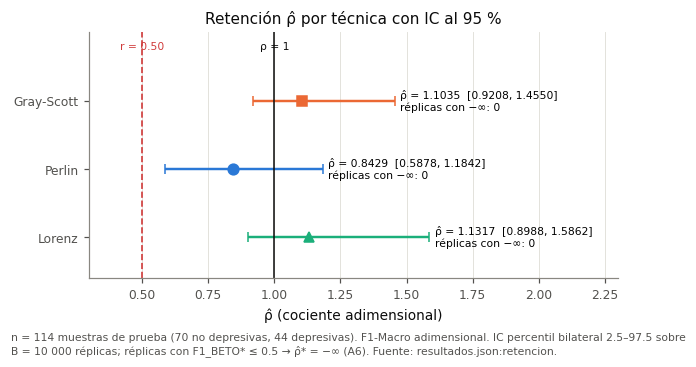

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f5_06_retencion.png')

In [9]:
fig, ax = plt.subplots(figsize=(6.2, 2.9))
for i, t in enumerate(TECHS):
    x = R['retencion'][t]
    lo, hi = x['interval']
    ax.errorbar(x['rho_obs'], 2 - i, xerr=[[x['rho_obs'] - lo], [hi - x['rho_obs']]], fmt=MARK[t], color=COL[t], ms=7, capsize=3)
    ax.text(hi + 0.02, 2 - i, f"ρ̂ = {x['rho_obs']:.4f}  [{lo:.4f}, {hi:.4f}]\nréplicas con −∞: {x['n_denominador_no_positivo']}",
            va='center', fontsize=7)
ax.axvline(1, color=style.INK, lw=1)
ax.axvline(0.5, color=style.THRESHOLD_COLOR, lw=1.1, ls='--')
ax.text(0.5, 2.75, 'r = 0.50', color=style.THRESHOLD_COLOR, ha='center', fontsize=7)
ax.text(1, 2.75, 'ρ = 1', color=style.INK, ha='center', fontsize=7)
ax.set_yticks([2, 1, 0], [LAB[t] for t in TECHS])
ax.set_xlim(0.3, 2.3)
ax.set_ylim(-0.6, 3.0)
ax.set_xlabel('ρ̂ (cociente adimensional)')
ax.set_title('Retención ρ̂ por técnica con IC al 95 %')
ax.grid(axis='x')
pie(fig, N_NOTE + ' IC percentil bilateral 2.5–97.5 sobre B = 10 000 réplicas; réplicas con F1_BETO* ≤ 0.5 → ρ̂* = −∞ (A6). '
    'Fuente: resultados.json:retencion.', y=-0.06)
guardar(fig, 'f5_06_retencion', 'F5.6: retención ρ̂ con IC 95 %, líneas en 1 y en r = 0.50')

**Lectura.**
- Los tres intervalos contienen 1 y quedan por encima de 0.50.
- Una ρ̂ observada mayor que 1 (Gray-Scott y Lorenz) cae dentro de un intervalo que contiene 1, así que **no se detecta pérdida**. No es una ganancia frente a BETO.

## 7. F5.5 — Veredictos por variante y tabla de robustez

Mapa de veredictos (V1–V4) por variante de sensibilidad (§8) y alternativa de robustez (A2, A3, A7, A12), y veredictos por semilla bajo A14.

Fuentes: `resultados.json:sensibilidad`, `robustez` y `veredictos.csv`.

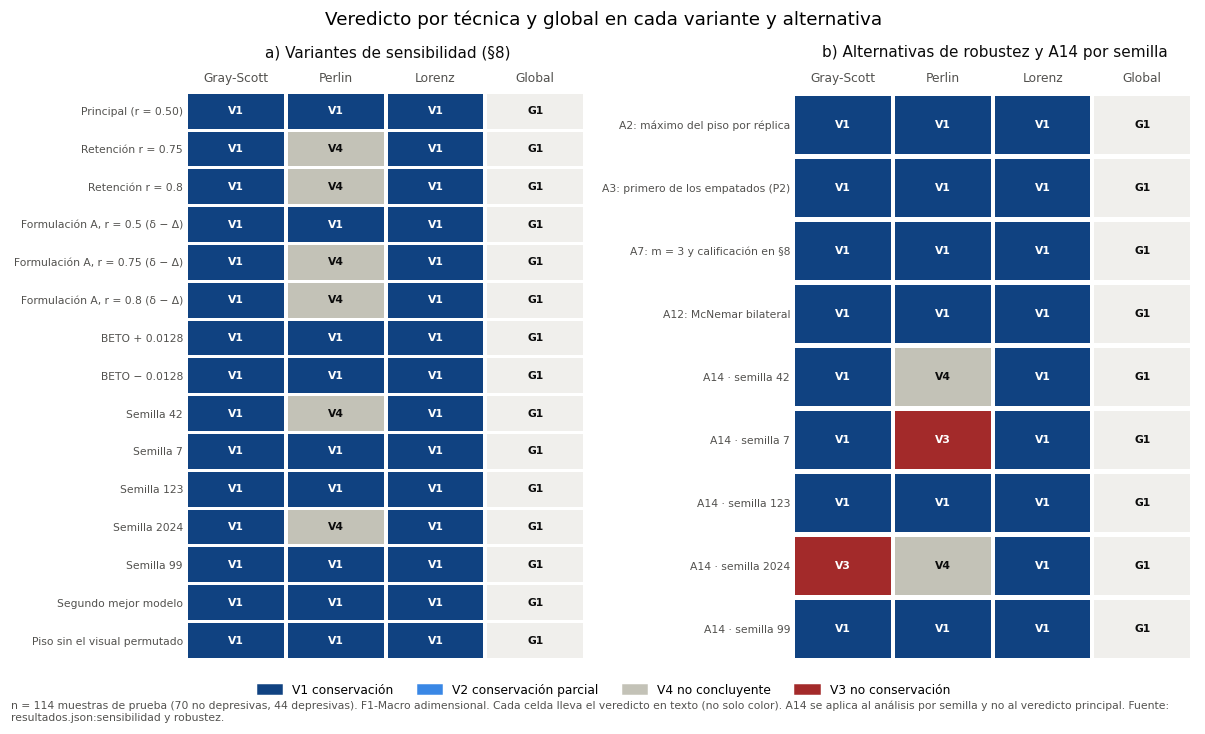

,Alternativa,Gray-Scott,Perlin,Lorenz,Global,Cambia (técnica),Cambia (global),Semillas con V1,Nota
0,A2: máximo por réplica,V1,V1,V1,G1,"Gray-Scott: no, Perlin: no, Lorenz: no",no,—,
1,"A3: primero de los empatados según pisos.order (Enmienda 5, P2)",V1,V1,V1,G1,"Gray-Scott: no, Perlin: no, Lorenz: no",no,—,sin empate en el máximo observado: igual al principal
2,A7: m = 3 y calificación en cada variante de §8,V1,V1,V1,G1,"Gray-Scott: no, Perlin: no, Lorenz: no",no,—,L solo califica; V y G no cambian
3,A12: McNemar bilateral frente a BETO y al techo,V1,V1,V1,G1,"Gray-Scott: no, Perlin: no, Lorenz: no",no,—,§7: McNemar no modifica veredictos
4,"A14: piso permutado de la semilla emparejada, si es mayor (por réplica; Enmienda 5, P1)",—,—,—,—,—,—,"Gray-Scott: 5→4, Perlin: 3→2, Lorenz: 5→5",


In [10]:
VCOL = {'V1': '#104281', 'V2': '#3987e5', 'V4': '#c3c2b7', 'V3': '#a32a2a'}
VTXT = {'V1': 'white', 'V2': 'white', 'V4': style.INK, 'V3': 'white'}
rows = [(lab, {t: res['techniques'][t]['verdict'] for t in TECHS}, res['global']) for lab, res in theta_rows()]
ALT_LAB = {'A2': 'A2: máximo del piso por réplica', 'A3': 'A3: primero de los empatados (P2)',
           'A7': 'A7: m = 3 y calificación en §8', 'A12': 'A12: McNemar bilateral'}
alt_rows = [(ALT_LAB[a['alternativa'].split(':')[0]], a['veredictos'], a['global']) for a in R['robustez'] if 'veredictos' in a]
a14 = next(a for a in R['robustez'] if a['alternativa'].startswith('A14'))
seed_rows = [(f'A14 · semilla {s}', x['veredictos'], x['global']) for s, x in a14['por_semilla'].items()]


def vmap(ax, rows, title):
    for i, (lab, v, g) in enumerate(rows):
        for j, key in enumerate(TECHS + ['global']):
            val = g if key == 'global' else v[key]
            fc = VCOL.get(val, '#ffffff') if key != 'global' else '#f0efec'
            ax.add_patch(plt.Rectangle((j, len(rows) - 1 - i), 0.96, 0.92, color=fc, lw=0))
            ax.text(j + 0.48, len(rows) - 1 - i + 0.46, val, ha='center', va='center', fontsize=7,
                    color=VTXT.get(val, style.INK) if key != 'global' else style.INK, fontweight='bold')
    ax.set_xlim(0, 4)
    ax.set_ylim(0, len(rows))
    ax.set_xticks(np.arange(4) + 0.48, [LAB[t] for t in TECHS] + ['Global'])
    ax.xaxis.tick_top()
    ax.set_yticks(np.arange(len(rows))[::-1] + 0.46, [r[0] for r in rows], fontsize=7)
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.set_title(title, pad=22)


fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 6.4), gridspec_kw={'width_ratios': [1, 1]})
vmap(a1, rows, 'a) Variantes de sensibilidad (§8)')
vmap(a2, alt_rows + seed_rows, 'b) Alternativas de robustez y A14 por semilla')
handles = [plt.Rectangle((0, 0), 1, 1, color=VCOL[k]) for k in ('V1', 'V2', 'V4', 'V3')]
fig.legend(handles, ['V1 conservación', 'V2 conservación parcial', 'V4 no concluyente', 'V3 no conservación'],
           loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('Veredicto por técnica y global en cada variante y alternativa')
fig.tight_layout(rect=(0, 0.04, 1, 1))
pie(fig, N_NOTE + ' Cada celda lleva el veredicto en texto (no solo color). A14 se aplica al análisis por semilla y no al '
    'veredicto principal. Fuente: resultados.json:sensibilidad y robustez.', y=0.0)
guardar(fig, 'f5_07_veredictos_robustez', 'F5.5: veredictos por variante de sensibilidad (a), alternativas de robustez y A14 por semilla (b)')

rob = pd.DataFrame([{'Alternativa': a['alternativa'],
                     **{LAB[t]: a.get('veredictos', {}).get(t, '—') for t in TECHS}, 'Global': a.get('global', '—'),
                     'Cambia (técnica)': ', '.join(f"{LAB[t]}: {'sí' if v else 'no'}" for t, v in a.get('cambia_tecnica', {}).items()) or '—',
                     'Cambia (global)': {True: 'sí', False: 'no'}.get(a.get('cambia_global'), '—'),
                     'Semillas con V1': ', '.join(f"{LAB[t]}: {R['sensibilidad']['por_semilla']['n_semillas_V1'][t]}→{a['n_semillas_V1'][t]}"
                                                  for t in TECHS) if 'n_semillas_V1' in a else '—',
                     'Nota': a.get('nota') or ''} for a in R['robustez']])
rob

**Lectura.**
- Ninguna alternativa de robustez cambia el veredicto principal ni el global.
- Bajo A14, el conteo de semillas con V1 baja de 5 a 4 en Gray-Scott y de 3 a 2 en Perlin; Lorenz se mantiene en 5.
- En la sensibilidad, Perlin obtiene V4 con r ≥ 0.75 y con las semillas 42 y 2024.

## 8. F5.4 — Cochran y McNemar

La tabla basta, porque un gráfico no aportaría más.
- Q de Cochran asintótica (gl = 2). No hay McNemar por pares, porque p ≥ 0.05.
- McNemar exacto unilateral frente a BETO y al techo 5D, con Holm dentro de cada familia.
  - b: errores solo de la referencia.
  - c: errores solo del visual.

Fuente: `resultados.json:mcnemar`.

In [11]:
m = R['mcnemar']
coch = pd.DataFrame([{'Contraste': 'Q de Cochran (3 finalistas)', 'Q': round(m['cochran']['Q'], 4), 'gl': m['cochran']['gl'],
                      'p': round(m['cochran']['p'], 4), 'Todos concordantes': m['cochran']['todos_concordantes'],
                      'McNemar por pares': 'no calculado (p ≥ 0.05)' if m['pares'] is None else 'sí'}])
mcn = pd.DataFrame([{'Referencia': {'beto': 'BETO', 'techo5d': 'Techo 5D'}[ref_], 'Técnica': LAB[t], 'b': x['b'], 'c': x['c'],
                     'Lado': x['lado'], 'p': round(x['p'], 4), 'Rango de Holm': x['rank'], 'α_h': round(x['alpha_h'], 4),
                     'Rechaza': 'sí' if x['reject'] else 'no'}
                    for ref_, fam in m['frente_a'].items() for t, x in fam.items()])
display(coch)
mcn

,Contraste,Q,gl,p,Todos concordantes,McNemar por pares
0,Q de Cochran (3 finalistas),3.2941,2,0.1926,False,no calculado (p ≥ 0.05)


,Referencia,Técnica,b,c,Lado,p,Rango de Holm,α_h,Rechaza
0,BETO,Gray-Scott,1,3,unilateral,0.9375,2,0.0250,no
1,BETO,Perlin,7,5,unilateral,0.3872,1,0.0167,no
2,BETO,Lorenz,3,7,unilateral,0.9453,3,0.0500,no
3,Techo 5D,Gray-Scott,1,4,unilateral,0.9688,3,0.0500,no
4,Techo 5D,Perlin,7,6,unilateral,0.5000,1,0.0167,no
5,Techo 5D,Lorenz,3,8,unilateral,0.9673,2,0.0250,no


**Lectura.**
- Ningún McNemar rechaza, tampoco con la alternativa bilateral (A12).
- Por el protocolo §7, esa no significancia **no** se interpreta como equivalencia.

## 9. F4.5 — Control de longitud

a) L = F1_img − F1_longitud por técnica, con su p y el rechazo de Holm (m = 3). `resultados.json` no registra un IC de L.
b) F1-Macro por tercil de `n_tokens_beto`, con los cortes calculados en `train`. Se muestran las cinco semillas de cada finalista, su media y BETO.
c) ρ de Spearman de u0–u4 con log(n_tokens_beto) y con truncated_128, en `train` (n = 908).

Fuentes: `resultados.json:longitud`, `terciles_longitud` y `spearman_u_longitud`.

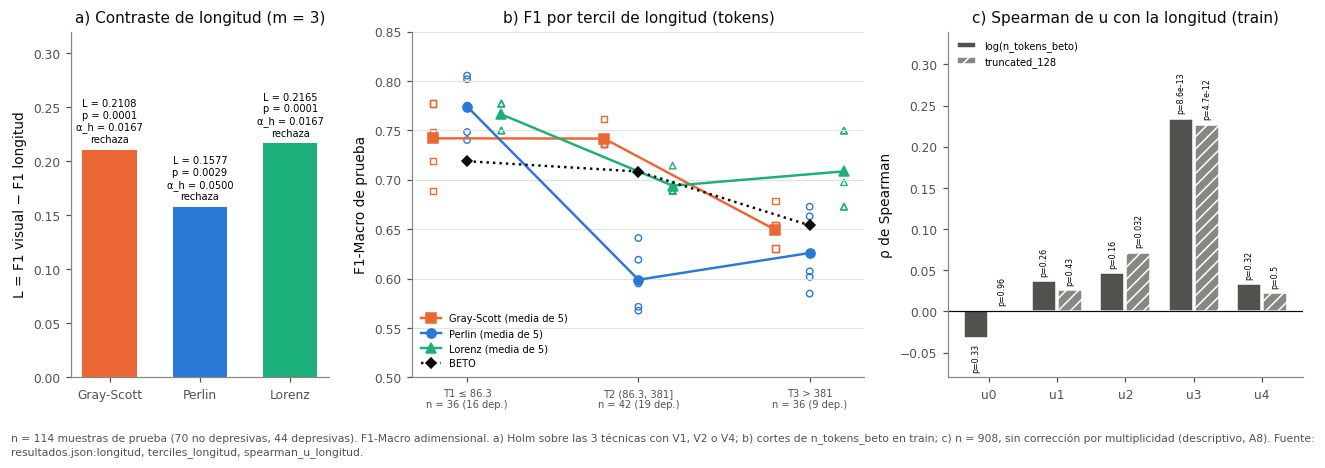

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f45_01_longitud.png')

In [12]:
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(12, 3.9), gridspec_kw={'width_ratios': [0.8, 1.4, 1.1]})
for i, t in enumerate(TECHS):
    x = R['longitud']['techniques'][t]
    a1.bar(i, x['L_obs'], color=COL[t], width=0.6)
    a1.text(i, x['L_obs'] + 0.005, f"L = {x['L_obs']:.4f}\np = {x['p']:.4f}\nα_h = {x['alpha_h']:.4f}\n"
            f"{'rechaza' if x['reject'] else 'no rechaza'}", ha='center', va='bottom', fontsize=6.5)
a1.set_xticks(range(3), [LAB[t] for t in TECHS])
a1.set_ylim(0, 0.32)
a1.set_ylabel('L = F1 visual − F1 longitud')
a1.set_title(f"a) Contraste de longitud (m = {R['longitud']['m']})")

T3 = R['terciles_longitud']
cuts = T3['cortes']
estr = list(T3['estratos'])
offs = {'gray_scott': -0.2, 'perlin': 0.0, 'lorenz': 0.2}
for t in TECHS:
    means = []
    for k, e in enumerate(estr):
        v = T3['estratos'][e][t]
        a2.scatter(np.full(5, k + offs[t]), v['por_semilla'], marker=MARK[t], facecolors='none', edgecolors=COL[t], s=18, lw=0.9)
        means.append(v['media'])
    a2.plot(np.arange(3) + offs[t], means, marker=MARK[t], color=COL[t], label=f'{LAB[t]} (media de 5)', ms=6)
a2.plot(range(3), [T3['estratos'][e]['beto'] for e in estr], marker='D', color=style.INK, ls=':', label='BETO', ms=5)
lab_e = [f"T1 ≤ {cuts[0]:.1f}\nn = {T3['estratos']['T1']['n']} ({T3['estratos']['T1']['n_dep']} dep.)",
         f"T2 ({cuts[0]:.1f}, {cuts[1]:.0f}]\nn = {T3['estratos']['T2']['n']} ({T3['estratos']['T2']['n_dep']} dep.)",
         f"T3 > {cuts[1]:.0f}\nn = {T3['estratos']['T3']['n']} ({T3['estratos']['T3']['n_dep']} dep.)"]
a2.set_xticks(range(3), lab_e, fontsize=6.5)
a2.set_ylabel('F1-Macro de prueba')
a2.set_ylim(0.5, 0.85)
a2.legend(fontsize=6.5, loc='lower left')
a2.set_title('b) F1 por tercil de longitud (tokens)')
a2.grid(axis='y')

S = R['spearman_u_longitud']
comps = ['u0', 'u1', 'u2', 'u3', 'u4']
w = 0.38
for k, (feat, lab_f, col_f, hatch) in enumerate([('log(n_tokens_beto)', 'log(n_tokens_beto)', style.INK_SECONDARY, None),
                                                  ('truncated_128', 'truncated_128', style.MUTED, '///')]):
    vals = [S[f'{u}__{feat}']['rho'] for u in comps]
    ps = [S[f'{u}__{feat}']['p'] for u in comps]
    xs = np.arange(5) + (k - 0.5) * w
    a3.bar(xs, vals, width=w * 0.92, color=col_f, hatch=hatch, edgecolor='white', label=lab_f)
    for x_, v_, p_ in zip(xs, vals, ps):
        a3.text(x_, v_ + (0.006 if v_ >= 0 else -0.006), f'p={p_:.2g}', ha='center', va='bottom' if v_ >= 0 else 'top',
                fontsize=5.2, rotation=90)
a3.axhline(0, color=style.INK, lw=0.8)
a3.set_xticks(range(5), comps)
a3.set_ylim(-0.08, 0.34)
a3.set_ylabel('ρ de Spearman')
a3.legend(fontsize=6.5, loc='upper left')
a3.set_title('c) Spearman de u con la longitud (train)')
fig.tight_layout()
pie(fig, N_NOTE + ' a) Holm sobre las 3 técnicas con V1, V2 o V4; b) cortes de n_tokens_beto en train; c) n = 908, sin '
    'corrección por multiplicidad (descriptivo, A8). Fuente: resultados.json:longitud, terciles_longitud, spearman_u_longitud.')
guardar(fig, 'f45_01_longitud', 'F4.5: L por técnica con p (a), F1 por tercil de longitud (b) y Spearman de u0–u4 con la longitud (c)')

**Lectura.**
- Las tres técnicas superan al clasificador de longitud: Holm rechaza en las tres y ningún veredicto se califica.
- Por terciles:
  - el F1 de BETO baja de T1 a T3;
  - Perlin cae en T2;
  - Lorenz es el más estable.
- Solo u3 muestra una correlación apreciable con la longitud y con el truncamiento.

## 10. F4.6 (parcial) — Concordancia, contención e intersección de errores

a) Kappa de Cohen sobre ŷ y sobre los vectores de acierto. No se calcularon pares entre técnicas (celdas en gris).
b) Contención C = |E_vis ∩ E_ref| / |E_vis| frente al techo 5D, a BETO y a 768D, con IC al 95 % y la referencia nula |E_ref| / n.
c) Intersección de errores entre BETO, el techo 5D y el finalista, en un diagrama de áreas no proporcionales.
- Los conteos salen de las predicciones de prueba ya archivadas (ŷ visual = media de `p_dep` de 5 semillas > 0.5).
- Antes se comprueba que reproducen los tamaños por par de `f46_resultados.json`.

**La condición 2 de la frase de F4.6 está pendiente de F4.1 (Enmienda 5, P6).** Hasta entonces solo se afirma lo siguiente: los errores visuales se concentran en los de **u** más de lo esperado por independencia.

Fuentes: `f46_resultados.json:kappa`, `contencion` y `contencion_por_semilla`.

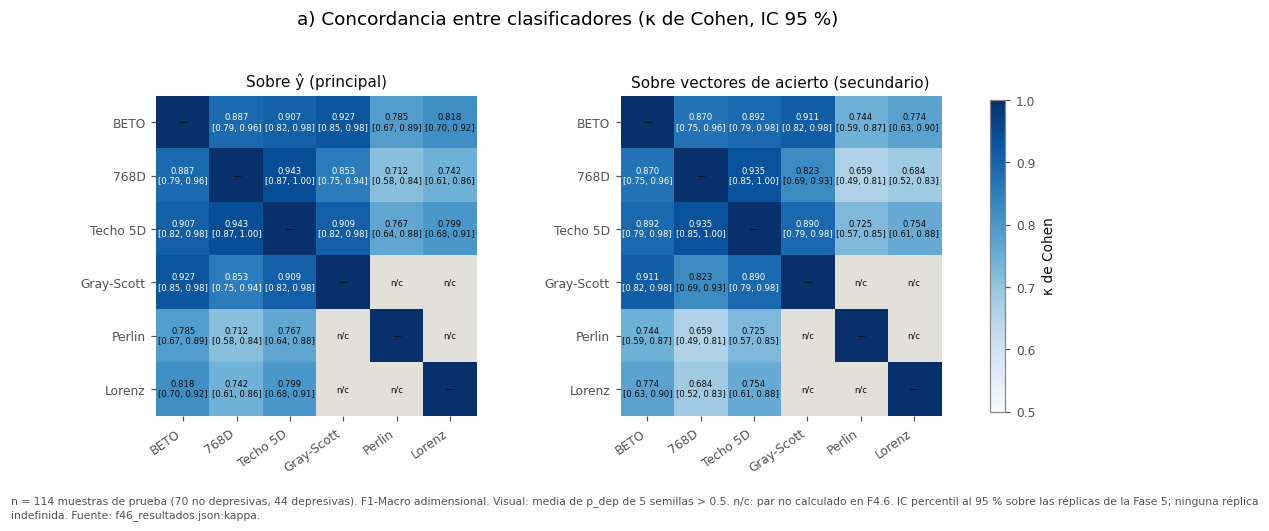

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f46_01_kappa.png')

In [13]:
NAMES = ['beto', 'emb768', 'techo5d'] + TECHS
NLAB = {'beto': 'BETO', 'emb768': '768D', 'techo5d': 'Techo 5D', **LAB}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), gridspec_kw={'wspace': 0.45})
cmap = plt.get_cmap('Blues').copy()
cmap.set_bad('#e1e0d9')
for ax, kind, title in zip(axes, ['y_hat', 'vector_acierto'], ['Sobre ŷ (principal)', 'Sobre vectores de acierto (secundario)']):
    M = np.full((6, 6), np.nan)
    for pair, x in F46['kappa'][kind].items():
        a_, b_ = pair.split('__')
        i, j = NAMES.index(a_), NAMES.index(b_)
        M[i, j] = M[j, i] = x['obs']
    np.fill_diagonal(M, 1.0)
    im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, vmin=0.5, vmax=1.0)
    for i in range(6):
        for j in range(6):
            if i == j:
                txt = '—'
            elif np.isnan(M[i, j]):
                txt = 'n/c'
            else:
                key = f'{NAMES[min(i, j)]}__{NAMES[max(i, j)]}'
                key = key if key in F46['kappa'][kind] else f'{NAMES[max(i, j)]}__{NAMES[min(i, j)]}'
                lo, hi = F46['kappa'][kind][key]['interval']
                txt = f'{M[i, j]:.3f}\n[{lo:.2f}, {hi:.2f}]'
            ax.text(j, i, txt, ha='center', va='center', fontsize=5.6,
                    color='white' if (not np.isnan(M[i, j]) and M[i, j] > 0.85 and i != j) else style.INK)
    ax.set_xticks(range(6), [NLAB[n] for n in NAMES], rotation=35, ha='right')
    ax.set_yticks(range(6), [NLAB[n] for n in NAMES])
    ax.set_title(title)
    for s in ax.spines.values():
        s.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label='κ de Cohen')
fig.suptitle('a) Concordancia entre clasificadores (κ de Cohen, IC 95 %)', x=0.45)
pie(fig, N_NOTE + ' Visual: media de p_dep de 5 semillas > 0.5. n/c: par no calculado en F4.6. IC percentil al 95 % sobre '
    'las réplicas de la Fase 5; ninguna réplica indefinida. Fuente: f46_resultados.json:kappa.', y=0.02)
guardar(fig, 'f46_01_kappa', 'F4.6: mapa de calor de κ de Cohen sobre ŷ y sobre vectores de acierto, con IC 95 %')

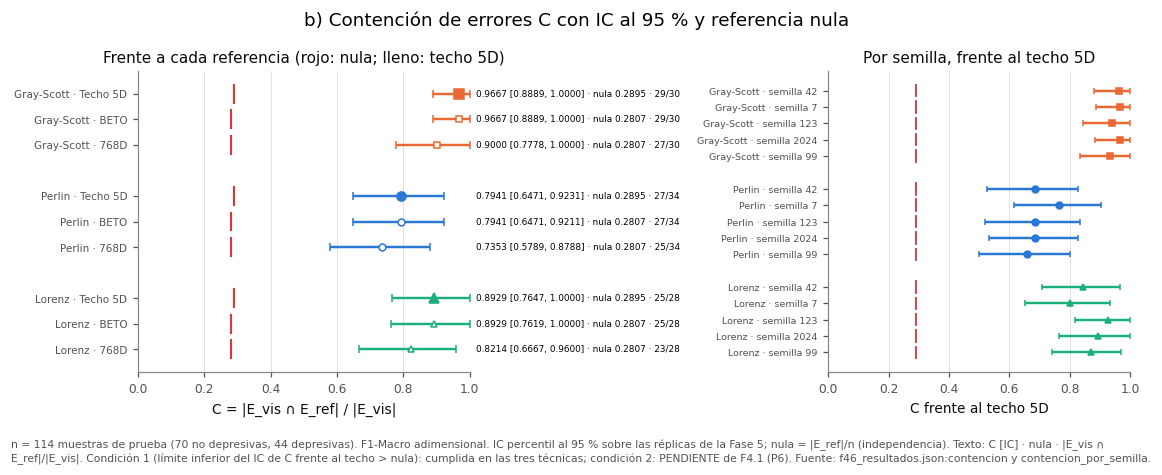

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f46_02_contencion.png')

In [14]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.9), gridspec_kw={'width_ratios': [1.1, 1]})
REFS = [('techo5d', 'Techo 5D'), ('beto', 'BETO'), ('emb768', '768D')]
for i, t in enumerate(TECHS):
    for k, (ref_, rl) in enumerate(REFS):
        x = F46['contencion'][t][ref_]
        y = (2 - i) * 4 + (2 - k)
        lo, hi = x['interval']
        a1.errorbar(x['C_obs'], y, xerr=[[x['C_obs'] - lo], [hi - x['C_obs']]], fmt=MARK[t], color=COL[t],
                    ms=6 if ref_ == 'techo5d' else 4.5, capsize=2.5, mfc=COL[t] if ref_ == 'techo5d' else 'white')
        a1.plot([x['nula_obs']] * 2, [y - 0.35, y + 0.35], color=style.THRESHOLD_COLOR, lw=1.4)
        a1.text(1.02, y, f"{x['C_obs']:.4f} [{lo:.4f}, {hi:.4f}] · nula {x['nula_obs']:.4f} · "
                f"{x['n_interseccion']}/{x['n_errores_vis']}", fontsize=5.8, va='center')
ylabels = {(2 - i) * 4 + (2 - k): f'{LAB[t]} · {rl}' for i, t in enumerate(TECHS) for k, (_, rl) in enumerate(REFS)}
a1.set_yticks(list(ylabels), list(ylabels.values()), fontsize=6.8)
a1.set_xlim(0, 1.0)
a1.set_xlabel('C = |E_vis ∩ E_ref| / |E_vis|')
a1.set_title('Frente a cada referencia (rojo: nula; lleno: techo 5D)')
a1.grid(axis='x')
for i, t in enumerate(TECHS):
    for k, s in enumerate(SEEDS):
        x = F46['contencion_por_semilla'][t][str(s)]
        lo, hi = x['interval']
        y = (2 - i) * 6 + (4 - k)
        a2.errorbar(x['C_obs'], y, xerr=[[x['C_obs'] - lo], [hi - x['C_obs']]], fmt=MARK[t], color=COL[t], ms=4.5, capsize=2)
        a2.plot([x['nula_obs']] * 2, [y - 0.35, y + 0.35], color=style.THRESHOLD_COLOR, lw=1.2)
a2.set_yticks([(2 - i) * 6 + (4 - k) for i in range(3) for k in range(5)],
              [f'{LAB[t]} · semilla {s}' for t in TECHS for s in SEEDS], fontsize=6.2)
a2.set_xlim(0, 1.0)
a2.set_xlabel('C frente al techo 5D')
a2.set_title('Por semilla, frente al techo 5D')
a2.grid(axis='x')
fig.suptitle('b) Contención de errores C con IC al 95 % y referencia nula')
fig.tight_layout()
pie(fig, N_NOTE + ' IC percentil al 95 % sobre las réplicas de la Fase 5; nula = |E_ref|/n (independencia). Texto: C [IC] · nula · '
    '|E_vis ∩ E_ref|/|E_vis|. Condición 1 (límite inferior del IC de C frente al techo > nula): cumplida en las tres técnicas; '
    'condición 2: PENDIENTE de F4.1 (P6). Fuente: f46_resultados.json:contencion y contencion_por_semilla.')
guardar(fig, 'f46_02_contencion', 'F4.6: contención C frente a la referencia nula con IC 95 %, por referencia y por semilla')

,Par,"Reconstruido (vis, ref, ∩)",f46_resultados.json,Coincide
0,Gray-Scott · techo5d,"(30, 33, 29)","(30, 33, 29)",True
1,Gray-Scott · beto,"(30, 32, 29)","(30, 32, 29)",True
2,Perlin · techo5d,"(34, 33, 27)","(34, 33, 27)",True
3,Perlin · beto,"(34, 32, 27)","(34, 32, 27)",True
4,Lorenz · techo5d,"(28, 33, 25)","(28, 33, 25)",True
5,Lorenz · beto,"(28, 32, 25)","(28, 32, 25)",True


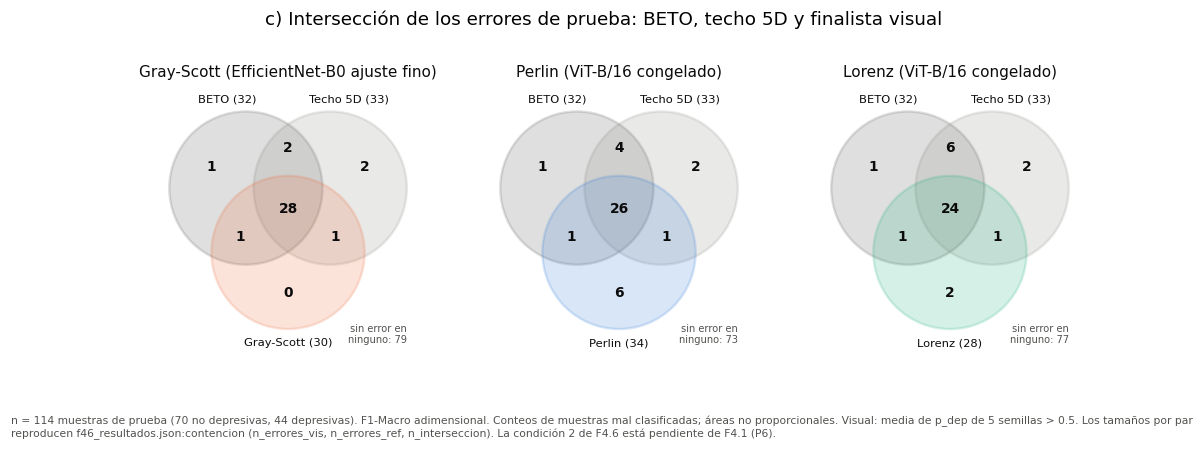

WindowsPath('C:/Users/DELL/Desktop/TT/TT2/ttdicevc/results/f5_contraste/figures/f46_03_interseccion_errores.png')

In [15]:
thr = cfg['modelos']['decision_threshold']
err = {'beto': bs.predict(ins.refs['beto'], thr) != ins.y, 'techo5d': bs.predict(ins.refs['techo5d'], thr) != ins.y}
venn_checks = []
for t in TECHS:
    err[t] = cx.yhat_mean(ins.visual[('final', t)]['p'], cfg) != ins.y
    for ref_ in ('techo5d', 'beto'):
        x = F46['contencion'][t][ref_]
        mine = (int(err[t].sum()), int(err[ref_].sum()), int((err[t] & err[ref_]).sum()))
        theirs = (x['n_errores_vis'], x['n_errores_ref'], x['n_interseccion'])
        venn_checks.append((f'{LAB[t]} · {ref_}', mine, theirs, mine == theirs))
VC = pd.DataFrame(venn_checks, columns=['Par', 'Reconstruido (vis, ref, ∩)', 'f46_resultados.json', 'Coincide'])
REPRO['venn'] = [{'par': r[0], 'coincide': bool(r[3])} for r in venn_checks]
(FIG / 'reproduccion_replicas.json').write_text(json.dumps(REPRO, indent=1, ensure_ascii=False) + '\n', encoding='utf-8')
if not VC['Coincide'].all():
    display(VC)
    raise RuntimeError('DETENIDO: los conteos de errores no reproducen f46_resultados.json')
display(VC)

fig, axes = plt.subplots(1, 3, figsize=(11, 4.0))
centers = {'beto': (-0.55, 0.32), 'techo5d': (0.55, 0.32), 'vis': (0.0, -0.52)}
for ax, t in zip(axes, TECHS):
    A, B_, C_ = err['beto'], err['techo5d'], err[t]
    regions = {
        'beto': (A & ~B_ & ~C_), 'techo5d': (~A & B_ & ~C_), 'vis': (~A & ~B_ & C_),
        'bt': (A & B_ & ~C_), 'bv': (A & ~B_ & C_), 'tv': (~A & B_ & C_), 'btv': (A & B_ & C_)}
    for key, col, lab in (('beto', style.INK_SECONDARY, f'BETO ({int(A.sum())})'),
                          ('techo5d', style.MUTED, f'Techo 5D ({int(B_.sum())})'),
                          ('vis', COL[t], f'{LAB[t]} ({int(C_.sum())})')):
        cx_, cy_ = centers[key]
        ax.add_patch(Circle((cx_, cy_), 1.0, facecolor=col, alpha=0.18, edgecolor=col, lw=1.6))
        ty = cy_ + 1.12 if key != 'vis' else cy_ - 1.22
        ax.text(cx_ + (-0.25 if key == 'beto' else 0.25 if key == 'techo5d' else 0), ty, lab, ha='center', fontsize=7.5,
                color=style.INK)
    pos = {'beto': (-1.0, 0.6), 'techo5d': (1.0, 0.6), 'vis': (0, -1.05), 'bt': (0, 0.85), 'bv': (-0.62, -0.32),
           'tv': (0.62, -0.32), 'btv': (0, 0.05)}
    for k, (x_, y_) in pos.items():
        ax.text(x_, y_, str(int(regions[k].sum())), ha='center', va='center', fontsize=9, fontweight='bold', color=style.INK)
    none_ = int((~A & ~B_ & ~C_).sum())
    ax.text(1.55, -1.7, f'sin error en\nninguno: {none_}', ha='right', fontsize=6.5, color=style.INK_SECONDARY)
    ax.set_xlim(-1.8, 1.8)
    ax.set_ylim(-1.95, 1.65)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(f'{LAB[t]} ({FINALISTA[t]})')
fig.suptitle('c) Intersección de los errores de prueba: BETO, techo 5D y finalista visual')
pie(fig, N_NOTE + ' Conteos de muestras mal clasificadas; áreas no proporcionales. Visual: media de p_dep de 5 semillas > 0.5. '
    'Los tamaños por par reproducen f46_resultados.json:contencion (n_errores_vis, n_errores_ref, n_interseccion). '
    'La condición 2 de F4.6 está pendiente de F4.1 (P6).', y=0.06)
guardar(fig, 'f46_03_interseccion_errores', 'F4.6: diagrama de intersección de errores (BETO, techo 5D, finalista) por técnica')

**Lectura.**
- **Concordancia:** es alta entre BETO, 768D y el techo 5D. Gray-Scott es el finalista con mayor κ frente a BETO y al techo, y Perlin el de menor.
- **Contención:** la condición 1 se cumple en las tres técnicas, también por semilla. El límite inferior del IC de C frente al techo supera la referencia nula (0.2895).
- **Intersección:** la mayor parte de los errores de cada finalista son compartidos con BETO y con el techo.
- **Pendiente:** la frase «consistente con que el visual hereda los errores de **u**» queda en suspenso hasta F4.1 (condición 2, P6).

## Figuras generadas

In [16]:
TABLA = pd.DataFrame(FIGS)
(FIG / 'figuras.json').write_text(json.dumps({'figuras': FIGS, 'segundos_kernel': round(time.time() - T0, 1)},
                                             indent=1, ensure_ascii=False) + '\n', encoding='utf-8')
print(f'{len(FIGS)} figuras; tiempo del kernel: {time.time() - T0:.1f} s')
TABLA

11 figuras; tiempo del kernel: 20.9 s


,archivo,figura
0,results/f5_contraste/figures/f5_01_f1_prueba_modelos.png,"F1-Macro de prueba de todos los clasificadores, con umbral θ = 0 y BETO"
1,results/f5_contraste/figures/f5_02_theta_forest.png,F5.2: θ con IC de Holm por técnica (a) y en cada variante de sensibilidad (b)
2,results/f5_contraste/figures/f5_03_superioridad_piso.png,F5.1: finalista frente a cada piso (a) y D con IC de Holm (b)
3,results/f5_contraste/figures/f5_04_distribuciones_bootstrap.png,Distribuciones bootstrap de θ* y D* por técnica (réplicas reconstruidas y verificadas)
4,results/f5_contraste/figures/f5_05_descomposicion_descriptores.png,"F5.3: cascada de la descomposición por etapa (a) y visual − descriptores (b), con IC 95 %"
5,results/f5_contraste/figures/f5_06_retencion.png,"F5.6: retención ρ̂ con IC 95 %, líneas en 1 y en r = 0.50"
6,results/f5_contraste/figures/f5_07_veredictos_robustez.png,"F5.5: veredictos por variante de sensibilidad (a), alternativas de robustez y A14 por semilla (b)"
7,results/f5_contraste/figures/f45_01_longitud.png,"F4.5: L por técnica con p (a), F1 por tercil de longitud (b) y Spearman de u0–u4 con la longitud (c)"
8,results/f5_contraste/figures/f46_01_kappa.png,"F4.6: mapa de calor de κ de Cohen sobre ŷ y sobre vectores de acierto, con IC 95 %"
9,results/f5_contraste/figures/f46_02_contencion.png,"F4.6: contención C frente a la referencia nula con IC 95 %, por referencia y por semilla"
